# Sales Forecasting

## 1. Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1. Loading the Dataset

In [2]:
train = pd.read_csv("../data/raw/train.csv")
features = pd.read_csv("../data/raw/features.csv")
stores = pd.read_csv("../data/raw/stores.csv")
test = pd.read_csv("../data/raw/test.csv")

### 1.2. Understand the columns

In [3]:
print("Train shape:", train.shape)
print("Features shape:", features.shape)
print("Stores shape:", stores.shape)
print("Test shape:", test.shape)

Train shape: (421570, 5)
Features shape: (8190, 12)
Stores shape: (45, 3)
Test shape: (115064, 4)


In [4]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [5]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [6]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [7]:
test.head()

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 13.3 MB


### 1.3. Basic Datset Investigation

#### A. Number of stores

Dataset covers 45 different stores.

In [9]:

train["Store"].nunique()

45

#### B. Number of departments

81 departments

In [10]:

train["Dept"].nunique()

81

#### C. Date range

In [11]:

print("Start date:", train["Date"].min())
print("End date:", train["Date"].max())

Start date: 2010-02-05
End date: 2012-10-26


#### D. Missing values

In [12]:
train.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

#### E. Duplicate rows

In [13]:
train.duplicated().sum()

np.int64(0)

#### F. Sales statistics

In [14]:
train["Weekly_Sales"].describe()

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64

The mean is considerably larger than the median.

That suggests the sales distribution is right-skewed.

There are some very high-sales observations pulling the mean upward.

### 1.4. Investigating the time-series structure

#### A. How many Store × Department combinations?

In [15]:
train[["Store", "Dept"]].drop_duplicates().shape[0]

3331

#### B. How many observations does Store 1, Department 1 have?

In [16]:
train[
    (train["Store"] == 1) &
    (train["Dept"] == 1)
].shape[0]

143

#### C. Look at that time series

In [17]:
store1_dept1 = train[
    (train["Store"] == 1) &
    (train["Dept"] == 1)
].copy()

store1_dept1.head(10)

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
5,1,1,2010-03-12,21043.39,False
6,1,1,2010-03-19,22136.64,False
7,1,1,2010-03-26,26229.21,False
8,1,1,2010-04-02,57258.43,False
9,1,1,2010-04-09,42960.91,False


#### D. Plot

Convert Date to datetime

In [18]:
train_clean = train.copy()
features_clean = features.copy()
test_clean = test.copy()
stores_clean = stores.copy()

train_clean["Date"] = pd.to_datetime(train_clean["Date"])
features_clean["Date"] = pd.to_datetime(features_clean["Date"])
test_clean["Date"] = pd.to_datetime(test_clean["Date"])

In [19]:
train_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(1), int64(2)
memory usage: 13.3 MB


Sort the data

In [20]:
train_clean = train_clean.sort_values(
    ["Store", "Dept", "Date"]
).reset_index(drop=True)

In [21]:
train_clean.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Plot

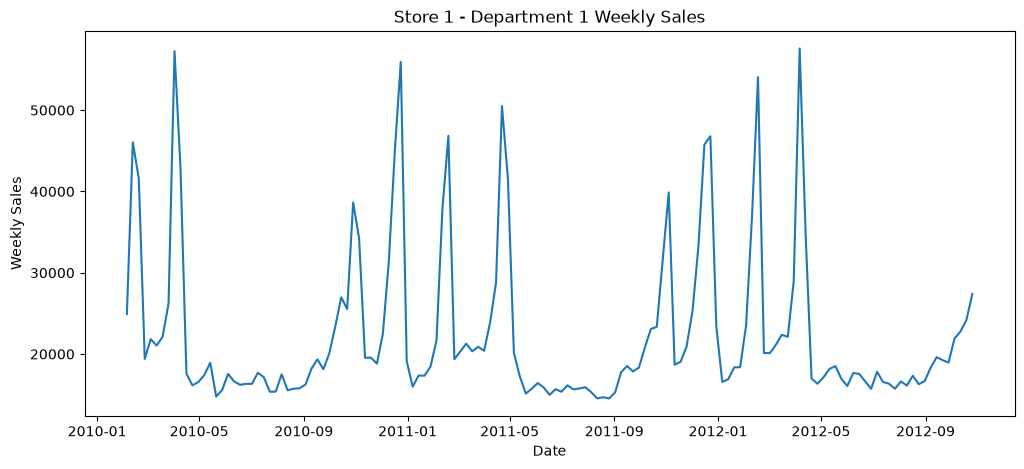

In [22]:
store1_dept1 = train_clean[
    (train_clean["Store"] == 1) &
    (train_clean["Dept"] == 1)
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    store1_dept1["Date"],
    store1_dept1["Weekly_Sales"]
)

plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.title("Store 1 - Department 1 Weekly Sales")

plt.show()

**Plot is telling us**

- Sales normally sit around 15,000–25,000
- Several weeks suddenly jump to 40,000–55,000+
- These spikes occur repeatedly across the years

That strongly suggests there is seasonality / recurring calendar behavior in the series.

### 1.5. Checking whether each Store × Department combination has a complete weekly history.

In [23]:
series_counts = (
    train_clean
    .groupby(["Store", "Dept"])
    .size()
)

series_counts.describe()

series_counts.value_counts().sort_index()

1        37
2        30
3        19
4        18
5        14
       ... 
139      11
140      11
141      15
142      17
143    2660
Name: count, Length: 136, dtype: int64

**Results**
- 3,331 unique Store × Department series
- Shortest series: 1 observation
- Longest series: 143 observations
- 2,660 series have the full 143 observations
- Therefore, 671 series do not have the full history

We should not assume every Store × Department combination has a complete weekly time series.

Some departments were probably introduced later, discontinued, or otherwise have shorter histories.

### 1.6. Finding the shortest and longest series

In [24]:
print("Shortest series:", series_counts.min())
print("Longest series:", series_counts.max())

print("Number of series with 143 observations:",
      (series_counts == 143).sum())

Shortest series: 1
Longest series: 143
Number of series with 143 observations: 2660


##### Investigating why series length is different ?

In [25]:
series_counts.sort_values().head(20)

Store  Dept
43     55      1
44     34      1
15     99      1
16     99      1
10     77      1
18     39      1
7      99      1
17     99      1
18     48      1
42     34      1
14     43      1
22     99      1
21     50      1
15     37      1
7      78      1
13     77      1
21     96      1
38     99      1
23     99      1
12     99      1
dtype: int64

These Store × Department combinations have only one recorded weekly sales observation.

A series with one observation cannot provide a meaningful historical trend or seasonal pattern on its own. However, that doesn't automatically mean its record is invalid.

Possible explanations include departments with limited histories or data coverage differences. We need more evidence before deciding.

##### How significant are the short series?

In [26]:
short_series = series_counts[series_counts < 50]

print("Number of series with fewer than 50 observations:",
      len(short_series))

print("Number of observations in these series:",
      short_series.sum())

Number of series with fewer than 50 observations: 336
Number of observations in these series: 4752


So, although 336 series have fewer than 50 observations, they account for only about 1.13% of all training rows.

##### Understanding department coverage

In [27]:
train_clean.groupby("Dept")["Store"].nunique().sort_values()

Dept
65     1
39     5
43     5
50    14
37    20
      ..
95    45
96    45
97    45
80    45
98    45
Name: Store, Length: 81, dtype: int64

This tells us that not every department operates in every store. Therefore, we shouldn't expect all possible Store × Department combinations to exist.

One important distinction: department coverage and historical coverage are different. A department can appear in a store but still have fewer recorded weeks than another department.

##### Investigate why some series are short

In [28]:
train_clean[
    (train_clean["Store"] == 43) &
    (train_clean["Dept"] == 55)
]

,Store,Dept,Date,Weekly_Sales,IsHoliday
401815,43,55,2011-03-04,-11.88,False


In [29]:
train_clean[
    (train_clean["Dept"] == 98)
].groupby("Store")["Date"].agg(["min", "max", "count"])

,min,max,count
Store,,,
1,2010-02-05,2012-10-26,143
2,2010-02-05,2012-10-26,143
3,2010-11-05,2012-08-03,36
4,2010-02-05,2012-10-26,143
5,2010-02-19,2012-08-10,23
6,2010-02-05,2012-10-26,143
7,2010-02-05,2012-10-26,141
8,2010-02-05,2012-10-26,143
9,2011-10-14,2012-05-18,14


Let's check whether a series has missing weeks

In [30]:
store3_dept98 = train_clean[
    (train_clean["Store"] == 3) &
    (train_clean["Dept"] == 98)
].copy()

print("Number of observations:", len(store3_dept98))
print("First date:", store3_dept98["Date"].min())
print("Last date:", store3_dept98["Date"].max())

Number of observations: 36
First date: 2010-11-05 00:00:00
Last date: 2012-08-03 00:00:00


In [31]:
date_gaps = store3_dept98["Date"].sort_values().diff().value_counts()

print(date_gaps)

Date
7 days      25
14 days      3
21 days      2
63 days      1
56 days      1
147 days     1
84 days      1
28 days      1
Name: count, dtype: int64


Identify the missing weeks

In [32]:
# Sort the dates into chronological order
dates = store3_dept98["Date"].sort_values()

# Calculate the gap between each date and the previous date
gaps = dates.diff()

# Keep dates where the gap is greater than 7 days
missing_intervals = gaps[gaps > pd.Timedelta(days=7)]

print(missing_intervals)

29490    63 days
29491    56 days
29492   147 days
29493    21 days
29497    14 days
29505    14 days
29511    14 days
29512    84 days
29514    28 days
29517    21 days
Name: Date, dtype: timedelta64[us]


Check whether this is unique to Store 3, Department 98

In [33]:
# Calculate the time between consecutive observations
# for every Store-Department combination.
date_gaps_all = (
    train_clean
    .sort_values(["Store", "Dept", "Date"])
    .groupby(["Store", "Dept"])["Date"]
    .diff()
)

# Count intervals longer than one week
long_gaps = date_gaps_all[
    date_gaps_all > pd.Timedelta(days=7)
]

print("Total intervals longer than 7 days:", len(long_gaps))
print("\nDistribution of gap lengths:")
print(long_gaps.value_counts().sort_index())

Total intervals longer than 7 days: 5447

Distribution of gap lengths:
Date
14 days     2346
21 days      862
28 days      517
35 days      338
42 days      214
            ... 
658 days       1
672 days       1
707 days       1
791 days       1
882 days       1
Name: count, Length: 79, dtype: int64


Measure the scale of the problem

In [34]:
# Identify gaps longer than 7 days
long_gaps = date_gaps_all[
    date_gaps_all > pd.Timedelta(days=7)
]

# Count distinct Store-Department combinations with long gaps
series_with_gaps = (
    train_clean.loc[long_gaps.index, ["Store", "Dept"]]
    .drop_duplicates()
    .shape[0]
)

total_series = train_clean.groupby(["Store", "Dept"]).ngroups

print("Total Store-Department series:", total_series)
print("Series with gaps longer than 7 days:", series_with_gaps)
print(
    "Percentage of series with gaps:",
    round(series_with_gaps / total_series * 100, 2),
    "%"
)

Total Store-Department series: 3331
Series with gaps longer than 7 days: 605
Percentage of series with gaps: 18.16 %


Overall date coverage

In [35]:
# Summarize the date coverage of each Store-Department series
series_summary = (
    train_clean
    .groupby(["Store", "Dept"])
    .agg(
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        observations=("Date", "count")
    )
    .reset_index()
)

# Inspect the series with the fewest observations
print(
    series_summary
    .sort_values("observations")
    .head(10)
)

      Store  Dept first_date  last_date  observations
3170     43    55 2011-03-04 2011-03-04             1
3224     44    34 2011-06-24 2011-06-24             1
1143     15    99 2012-07-20 2012-07-20             1
1219     16    99 2012-07-06 2012-07-06             1
738      10    77 2011-11-25 2011-11-25             1
1332     18    39 2010-05-14 2010-05-14             1
529       7    99 2012-05-11 2012-05-11             1
1295     17    99 2012-10-05 2012-10-05             1
1340     18    48 2010-02-19 2010-02-19             1
3101     42    34 2011-03-04 2011-03-04             1


Quantify how many series have short histories

In [36]:
# Count observations in each Store-Department series
series_counts = (
    train_clean
    .groupby(["Store", "Dept"])
    .size()
)

# Summarize the history lengths
print("Series with fewer than 10 observations:",
      (series_counts < 10).sum())

print("Series with fewer than 50 observations:",
      (series_counts < 50).sum())

print("Series with at least 100 observations:",
      (series_counts >= 100).sum())

print("Series with all 143 observations:",
      (series_counts == 143).sum())

Series with fewer than 10 observations: 164
Series with fewer than 50 observations: 336
Series with at least 100 observations: 2879
Series with all 143 observations: 2660


- 164 series have fewer than 10 observations. These are generally too short for standalone time-series forecasting.

- 336 series have fewer than 50 observations. Some forecasting methods may still work, but we need to assess them individually.

- 2,879 series have at least 100 observations. Most series have substantial historical coverage.

- 2,660 series have all 143 observations. This is a strong starting point for studying weekly sales patterns.